In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready to use!')

# DuckDuckGo
# Wikipedia
# TavillySearch

Model is ready to use!


In [2]:
from dotenv import load_dotenv, find_dotenv
import os

env_path = find_dotenv()
load_dotenv(env_path)
tavilyApikey = os.getenv('TAVILY_API_KEY')
print(tavilyApikey)

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


In [4]:
# Tools definition
from langchain_community.tools import tool
from langchain_community.tools import DuckDuckGoSearchResults, WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from tavily import TavilyClient

@tool
def get_news(query: str) -> str:
    """Helps to get news details for a specific subject"""
    duckDuckGoTool = DuckDuckGoSearchResults()
    return duckDuckGoTool.invoke(query)

#@tool
#def get_blog(subject: str) -> str:
#    """Gets the detailed blog on the subject using wikipedia"""
#    wikipediaWrapper = WikipediaAPIWrapper(top_k_results=2, doc_content_chars_max=500)
#    wikipediaTool = WikipediaQueryRun(api_wrapper=wikipediaWrapper)
#    result = wikipediaTool.run({"query": subject})
#    print(f'Wikipedia result {result}')
#    return f'Wikipedia result {result}' 

#@tool
#def web_search(search_query: str) -> str:
#    """Web search tool that searches web pages over internet for the given search query"""
#    tavily_client = TavilyClient(api_key=tavelyApiKey)
#    response = tavily_client.search(search_query)
#    return response

@tool
def web_search(search_query: str) -> str:
    """Web search tool that searches web pages over internet for the given search query"""
    tavily_client = TavilyClient(api_key=tavilyApikey)
    response = tavily_client. search(search_query)
    return response

C:\Users\User\AppData\Local\Temp\ipykernel_29336\137697523.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import tool


AI Agent is created successfully..


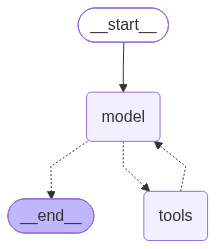

In [5]:
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools=[get_news, web_search],
    system_prompt="You are a helpful assistant. Please suggest the tool get_weather if someone asks for weather information. Please suggest get_stock_price tool if someone asks about stock price of a given stock."
)
print("AI Agent is created successfully..")
agent

In [6]:
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "What are the headlines on the subject middle east war?"}
    ]
})
response

InvalidAPIKeyError: Invalid API key: Unauthorized: missing or invalid API key.

In [7]:
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "Please give me a blog on global warming"}
    ]
})
response

{'messages': [HumanMessage(content='Please give me a blog on global warming', additional_kwargs={}, response_metadata={}, id='8d2304d1-db2a-4779-8b97-6dea9a0e0d11'),
  AIMessage(content="**The Planet in Peril: A Comprehensive Look at Global Warming**\n\n*Published: October\u202f30\u202f2026*  \n*Author: ChatGPT, Climate Communications Specialist*  \n\n---\n\n## Table of Contents\n\n1. **What Is Global Warming?**  \n2. **The Science Behind the Heat**  \n3. **Key Indicators: How We Know the Planet Is Warming**  \n4. **Impacts on Natural Systems**  \n   - 4.1 Oceans & Sea Level Rise  \n   - 4.2 Ice & Snowpack Loss  \n   - 4.3 Weather Extremes  \n   - 4.4 Biodiversity & Ecosystems  \n5. **Human Consequences**  \n   - 5.1 Health & Heat Stress  \n   - 5.2 Food & Water Security  \n   - 5.3 Economic Costs  \n   - 5.4 Climate Migration & Conflict  \n6. **Root Causes: Emissions and Beyond**  \n7. **What We’re Doing: Mitigation & Adaptation**  \n   - 7.1 International Agreements  \n   - 7.2 Renew

In [8]:
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "Search for best restaurant in Pune"}
    ]
})
response

InvalidAPIKeyError: Invalid API key: Unauthorized: missing or invalid API key.